# 04 · Classifier

**Goal:** replace the hand-set rules from notebook 03 with models that learn from the data, then compare them with the rules and the CMID-only baseline on the same scorecard.

The classifier works in two steps, the standard setup for record matching:
1. **Score every pair.** For each (entry, candidate matter) row in the pairs table, a model gives the probability that it's the right matter.
2. **Decide the action.** A second model looks at the whole entry (how the top candidates score, how many parts the narrative has, whether the typed client is known, and whether the wording mentions other work) and gives the probability that the top pick is safe to accept, that the entry covers more than one matter, or that it's a new client or matter. Cutoffs tuned on TRAIN turn those into one of the five decisions.

Each decision also gets a short and a full reason in plain language, built from that entry's own clues.

**What counts as good:** at least 98% of the decisions made with no person (`AUTO_MATCH` and `NO_MATCH`) are right, and as many entries as possible are decided that way (the **straight-through rate**).

**Questions**
1. Which model ranks the right matter first most often: logistic regression or gradient boosting?
2. Can its probabilities be trusted as confidence scores?
3. How far does a one-step version (cutoffs on the top probabilities) get, and what holds it back?
4. Does the second step reach the 98% target, and at what straight-through rate?
5. Which clues matter most?
6. Do the results hold on VAL?
7. What does a reviewer see for each decision?

## 1. Setup

In [1]:
import itertools
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, log_loss
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../src")
from rules import ACTIONS, OUTCOMES, answer_key, pick_best, precision_ci, run_rules, score, cmid_only, summarize
from classifier import (top_candidates, route, top_k_accuracy, entry_features, action_labels, route_actions,
                        multi_text_model, explain, ACTION_FEATURES)

In [2]:
RESULTS_DIR = Path("../results")
SEED = 210

LR_GRID = {"logisticregression__C": [0.01, 0.1, 1, 10]}
GB_GRID = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "min_samples_leaf": [20, 100, 200]}
ROUTE_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999],
    "multi_min": [0.5, 0.7, 0.9],
    "no_match_max": [0.02, 0.05, 0.1, 0.2],
}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.9, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2   # a missed multi-matter entry counts about twice as much as a false alarm (section 7)
ACTION_GB_GRID = {"max_iter": [50, 100, 200], "min_samples_leaf": [50, 100, 200]}
TEXT_GRID = {"logisticregression__C": [0.3, 1, 3, 10]}

## 2. Load data

Same pairs table as notebook 03: 103 rows per entry, one per candidate matter. `is_true_matter` is the label (1 for the right matter, and for both matters of a multi-matter entry), and `fold` assigns each TRAIN entry to one of notebook 02's 5 cross-validation folds. The clue columns come from notebook 02's config, and the answer key (`key_` columns) is only used for labels and scoring. The parts table (one row per piece of work) is only used to suggest how to divide multi-matter entries.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
baseline = pd.read_csv(RESULTS_DIR / "03_comparison.csv")
answers = answer_key(pairs)
parts = pd.read_parquet(RESULTS_DIR / "02_parts.parquet")
narratives = pairs.drop_duplicates("entry_id").set_index("entry_id")["narrative_norm"]

feature_groups = feature_config["features"]
FEATURES = [col for cols in feature_groups.values() for col in cols]
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]
PRECISION_TARGET = rules_config["precision_target"]

train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
X_train, y_train = train_pairs[FEATURES], train_pairs["is_true_matter"]
cv = PredefinedSplit(train_pairs["fold"])

assert (pairs.groupby("entry_id").size() == pairs["cmid"].nunique()).all()
assert pairs[FEATURES].notna().all().all()
assert train_pairs.groupby("entry_id")["fold"].nunique().eq(1).all()
print(f"{len(FEATURES)} features | TRAIN: {train_pairs['entry_id'].nunique():,} entries ({len(train_pairs):,} pairs) | "
      f"VAL: {val_pairs['entry_id'].nunique():,} entries | right matter in {y_train.mean():.1%} of TRAIN pairs")

46 features | TRAIN: 2,802 entries (288,606 pairs) | VAL: 601 entries | right matter in 1.0% of TRAIN pairs


- About 1 in 100 pairs is the right matter, so **row accuracy is useless here**: a model that always says "no" would be 99% accurate. Everything below is measured per entry instead.

## 3. How the classifier decides

**Step 1: score every pair.** Two models are compared:
- **Logistic regression:** one weight per clue, easy to read, a good sanity check.
- **Gradient boosting** (`HistGradientBoostingClassifier`): many small decision trees, each fixing the last one's mistakes. It can pick up combinations ("typed client matches *and* the timekeeper billed it") that one weight per clue can't. It's the usual choice for tables of features like this one.

**Keeping entries together.** All 103 rows of an entry have to land in the same fold, or the model would see part of an entry while training and get graded on the rest of it. Notebook 02 assigned each TRAIN entry to a fold and built the past-narrative clue with those same folds, so `PredefinedSplit` cross-validates on exactly those folds.

**Step 2: decide the action.** First a one-step version for comparison (`route` in `src/classifier.py`): cutoffs on the top two probabilities, tried in this order.

| # | if... | then |
|---|---|---|
| 1 | no candidate scores above `no_match_max` | `NO_MATCH` |
| 2 | the second-best candidate scores at least `multi_min` | `MULTI_MATTER` with both matters |
| 3 | a valid typed CMID isn't the top pick, or the typed matter wasn't open | `FLAG_MISMATCH`, suggesting the top pick |
| 4 | the top pick scores at least `auto_min` but wasn't open on the work date | `FLAG_MISMATCH` |
| 5 | the top pick scores at least `auto_min` | `AUTO_MATCH` |
| 6 | otherwise | `NEEDS_REVIEW` with the top 3 as a shortlist |

Then the **action model** (section 7), which replaces the cutoffs on raw probabilities with learned probabilities for each action.

**Scoring** is the same as notebook 03 (`score` and `summarize` in `src/rules.py`). Cutoffs are picked with the same rule: among settings with `decided_precision` of at least 98%, the highest `straight_through`; if none reach 98%, the highest precision to the half point.

## 4. Step 1: tune and compare the two models (TRAIN)

Each grid is searched over the 5 folds from notebook 02, scored by **log loss** (how far the probabilities are from the true 0/1 labels, lower is better). Gradient boosting stops adding trees once a held-out slice of the training fold stops improving (`early_stopping`). The gradient boosting grid takes a few minutes.

In [4]:
searches = {
    "logistic regression": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                                        LR_GRID, cv=cv, scoring="neg_log_loss"),
    "gradient boosting": GridSearchCV(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED),
                                      GB_GRID, cv=cv, scoring="neg_log_loss"),
}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: {search.best_params_} | log loss {-search.best_score_:.4f}")

logistic regression: {'logisticregression__C': 10} | log loss 0.0136
gradient boosting: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} | log loss 0.0094


In [5]:
gb_grid = pd.DataFrame(searches["gradient boosting"].cv_results_)
gb_grid["log_loss"] = -gb_grid["mean_test_score"]
gb_grid[["param_learning_rate", "param_max_leaf_nodes", "param_min_samples_leaf", "log_loss", "mean_fit_time"]].sort_values("log_loss").round(4)

,param_learning_rate,param_max_leaf_nodes,param_min_samples_leaf,log_loss,mean_fit_time
4,0.05,31,100,0.0094,6.8827
5,0.05,31,200,0.0095,7.8970
1,0.05,15,100,0.0096,7.7796
2,0.05,15,200,0.0097,6.1942
3,0.05,31,20,0.0098,6.6163
11,0.10,31,200,0.0101,4.5504
10,0.10,31,100,0.0102,4.2626
8,0.10,15,200,0.0102,3.5634
7,0.10,15,100,0.0105,3.3445
0,0.05,15,20,0.0105,3.7341


- A smaller learning rate (0.05) with larger leaves (`min_samples_leaf` 100 or 200) works best. Leaves that need more rows keep the trees from memorizing single entries.
- The settings with `min_samples_leaf` 20 and learning rate 0.1 do worst, with up to about twice the log loss of the best.

### Cross-validated probabilities

Each model with its best settings is refit fold by fold, so every TRAIN entry gets probabilities from a model that never saw it. Everything tuned in sections 6 and 7 uses these. **Top-1** is the share of entries whose right matter is ranked first, and **top-3** is the share where it's in the top three (what a reviewer's shortlist would show).

In [6]:
cv_probs = {name: cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
            for name, search in searches.items()}

model_scores = pd.DataFrame({name: {"log_loss": log_loss(y_train, p),
                                    "top_1": top_k_accuracy(train_pairs, p, k=1),
                                    "top_3": top_k_accuracy(train_pairs, p, k=3)}
                             for name, p in cv_probs.items()}).T
chosen_model = model_scores["top_1"].idxmax()
best_model = searches[chosen_model].best_estimator_
print("Chosen model:", chosen_model)
model_scores.round(3)

Chosen model: gradient boosting


,log_loss,top_1,top_3
logistic regression,0.014,0.855,0.952
gradient boosting,0.009,0.918,0.972


- **Gradient boosting ranks the right matter first for 92% of entries**, vs. 86% for logistic regression, and has it in the top 3 for 97%.
- Its log loss is also about a third lower, so the gain isn't just in the ranking: the probabilities themselves are closer to the truth.

## 5. Can the probabilities be trusted?

Cutoffs only make sense if a 0.9 really means "right about 9 times in 10". A **calibration plot** checks this: candidates are grouped by predicted probability, and each group's predicted average is plotted against how often it was actually the right matter. A calibrated model sits on the diagonal.

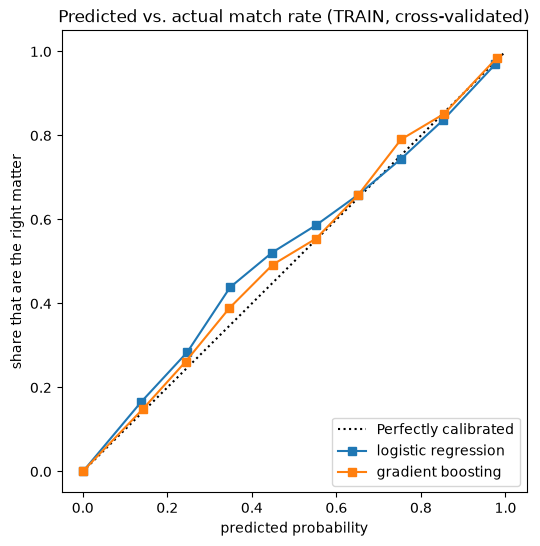

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in cv_probs.items():
    CalibrationDisplay.from_predictions(y_train, p, n_bins=10, name=name, ax=ax)
ax.set(title="Predicted vs. actual match rate (TRAIN, cross-validated)", xlabel="predicted probability", ylabel="share that are the right matter")
plt.show()

- Gradient boosting stays close to the diagonal (a little under-confident between 0.3 and 0.5), so its probabilities can be used as confidence scores without an extra calibration step.
- Logistic regression drifts further from it in the middle (0.3 to 0.6), another reason to prefer gradient boosting.

## 6. One step: cutoffs on the top probabilities (TRAIN)

Every combination of the three cutoffs is tried on the cross-validated probabilities (108 combinations).

In [8]:
ranked_train = top_candidates(train_pairs, cv_probs[chosen_model])

one_sweep = {}
for settings in itertools.product(*ROUTE_GRID.values()):
    one_sweep[settings] = summarize(score(route(ranked_train, dict(zip(ROUTE_GRID, settings))), answers))
one_sweep = pd.DataFrame(one_sweep).T.rename_axis(list(ROUTE_GRID))

one_step = {k: float(v) for k, v in zip(ROUTE_GRID, pick_best(one_sweep, PRECISION_TARGET))}
scored_one = score(route(ranked_train, one_step), answers)
wrong_one = scored_one[scored_one["outcome"] == "Accepted, wrong"]
print("Cutoffs:", one_step)
print({k: round(v, 3) for k, v in summarize(scored_one).items() if k in ["decided_precision", "straight_through", "review_share"]})
wrong_one["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

Cutoffs: {'auto_min': 0.98, 'multi_min': 0.5, 'no_match_max': 0.02}
{'straight_through': 0.449, 'decided_precision': 0.94, 'review_share': 0.434}


,wrong auto-accepts
key_entry_category,
MULTI_UNNAMED,38
MULTI_NAMED,27
WRONG_CMID_TEXT,3
NO_MATCH,1


- **One step tops out around 94%.** Nothing reaches 98%, so the rule falls back to the most precise setting (to the half point), with `auto_min` 0.98, which decides about 45% of entries with no person.
- **Almost every leftover error is a multi-matter entry** (65 of 69): the right matter is accepted, but the entry covered two matters. A cutoff on one candidate's probability can't see that, so it's what step 2 is for.

## 7. Step 2: an action model

Each TRAIN entry gets one row of entry-level clues (`entry_features` in `src/classifier.py`): the top three probabilities and their total, whether the top two are the same client, how the typed CMID compares, the top picks' past-narrative scores, the best typed-name scores, and narrative counts (parts, task types, matters and clients named). The label is what should happen to the entry (`action_labels`):

| label | when |
|---|---|
| `multi` | the entry covers more than one matter |
| `no_match` | the client or matter isn't in Matter Master |
| `auto` | otherwise, and the top pick is the right matter |
| `review` | otherwise (the top pick is wrong) |

A second gradient boosting model learns these labels from the cross-validated step-1 probabilities, using the same folds, so step 2 never sees probabilities from a model that saw the entry. Its number of trees and leaf size are tuned on those folds by log loss, like step 1. Early stopping is off here: it holds out a random slice of entries, and with only about 2,800 TRAIN entries the result depends too much on which ones land in that slice.

**Narrative score.** Multi-matter entries are hard to spot from scores alone: block-billed entries also have several parts, and many multi-matter narratives never name the second matter ("misc. calls for other client"). So the action model also gets a score from a small text model (`multi_text_model`: TF-IDF on words and word pairs, then logistic regression). It reads only the narrative and learns wording that signals other work. Its strength (`C`) is tuned on the same folds, and TRAIN entries get out-of-fold scores, so the action model never sees a score from a model trained on that entry.

In [9]:
entries_train = entry_features(train_pairs, cv_probs[chosen_model], CLIENT_COL, MATTER_COL)
labels = action_labels(entries_train, answers)
entry_folds = entries_train["entry_id"].map(train_pairs.drop_duplicates("entry_id").set_index("entry_id")["fold"])
entry_cv = PredefinedSplit(entry_folds)

narrative_train = entries_train["entry_id"].map(narratives)
is_multi = labels == "multi"
text_search = GridSearchCV(multi_text_model(), TEXT_GRID, cv=entry_cv, scoring="neg_log_loss").fit(narrative_train, is_multi)
text_model = text_search.best_estimator_
entries_train["multi_text_score"] = cross_val_predict(text_model, narrative_train, is_multi, cv=entry_cv, method="predict_proba")[:, 1]

action_search = GridSearchCV(HistGradientBoostingClassifier(learning_rate=0.05, early_stopping=False, random_state=SEED),
                             ACTION_GB_GRID, cv=entry_cv, scoring="neg_log_loss")
action_search.fit(entries_train[ACTION_FEATURES], labels)
action_model = action_search.best_estimator_
action_cv = pd.DataFrame(cross_val_predict(action_model, entries_train[ACTION_FEATURES], labels, cv=entry_cv, method="predict_proba"),
                         columns=action_model.classes_)
print(f"text model: {text_search.best_params_} | action model: {action_search.best_params_} | log loss {-action_search.best_score_:.3f}")
pd.Series(labels).value_counts().rename("TRAIN entries").to_frame()

text model: {'logisticregression__C': 10} | action model: {'max_iter': 50, 'min_samples_leaf': 50} | log loss 0.311


,TRAIN entries
auto,2249
review,205
no_match,174
multi,174


In [10]:
words = pd.Series(text_model[-1].coef_[0], index=text_model[0].get_feature_names_out())
words.nlargest(12).round(2).rename("weight toward multi-matter").to_frame()

,weight toward multi-matter
other,11.28
for,8.57
separate,5.27
to separate,5.27
on other,5.11
transaction,4.85
re unrelated,4.80
unrelated,4.80
for other,4.71
different,4.58


- **The words that push hardest toward multi-matter are about other work:** "other", "separate", "unrelated", "different transaction", "for other". None of them name a matter, which is why scores alone miss these entries.
- The tuning picks the largest `C` (10), so the model leans on these words heavily. That works here because the synthetic data reuses the same phrases. Real narratives will be more varied, so the text model would need retraining on real entries.

### Tune the action cutoffs (TRAIN)

`route_actions` uses the same order as the one-step version, but on the action model's probabilities: `NO_MATCH` if P(no_match) is at least `no_match_min`, `MULTI_MATTER` if P(multi) is at least `multi_min`, then flags, then `AUTO_MATCH` if P(auto) is at least `auto_min`, otherwise review.

**`multi_min` is learned first, on its own,** as the cutoff on P(multi) with the best **F2 score** on the cross-validated predictions. The two possible mistakes don't cost the same:
- A **missed** multi-matter entry goes to regular review, where someone could confirm one matter and miss the second, so part of the time is billed wrong or lost.
- A **false alarm** costs a reviewer a few seconds.

F2 counts a miss about twice as much as a false alarm (`MULTI_BETA`). A firm that weighs them differently can change that one setting and the cutoff is relearned.

**Then `auto_min` and `no_match_min`** are tuned with `multi_min` fixed (45 combinations), and two sets are kept:
- **Strict:** the 98% target, with the highest straight-through rate.
- **Balanced:** the highest straight-through rate that still matches the rules' decided precision on TRAIN, to show how much more the classifier can automate at the rules' accuracy.

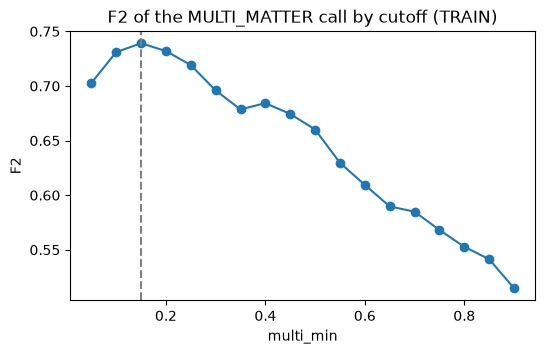

multi_min = 0.15


In [11]:
multi_score = pd.Series({t: fbeta_score(is_multi, action_cv["multi"] >= t, beta=MULTI_BETA) for t in MULTI_GRID})
multi_min = float(multi_score.idxmax())
ax = multi_score.plot(marker="o", figsize=(6, 3.5), title=f"F{MULTI_BETA} of the MULTI_MATTER call by cutoff (TRAIN)")
ax.axvline(multi_min, color="gray", linestyle="--")
ax.set(xlabel="multi_min", ylabel=f"F{MULTI_BETA}")
plt.show()
print(f"multi_min = {multi_min}")

In [12]:
two_sweep = {}
for settings in itertools.product(*ACTION_GRID.values()):
    cfg = dict(zip(ACTION_GRID, settings)) | {"multi_min": multi_min}
    two_sweep[settings] = summarize(score(route_actions(entries_train, action_cv, cfg), answers))
two_sweep = pd.DataFrame(two_sweep).T.rename_axis(list(ACTION_GRID))

rules_precision = baseline.query("method == 'rules' and split == 'TRAIN' and entry_set == 'all'")["decided_precision"].iloc[0]
strict = {k: float(v) for k, v in zip(ACTION_GRID, pick_best(two_sweep, PRECISION_TARGET))} | {"multi_min": multi_min}
balanced = {k: float(v) for k, v in zip(ACTION_GRID, pick_best(two_sweep, rules_precision))} | {"multi_min": multi_min}
print("Strict:", strict, "| Balanced:", balanced)

pd.DataFrame({"one step": one_sweep.loc[tuple(one_step.values())],
              "two steps, strict": two_sweep.loc[(strict["auto_min"], strict["no_match_min"])],
              "two steps, balanced": two_sweep.loc[(balanced["auto_min"], balanced["no_match_min"])]}).T[
    ["decided_precision", "straight_through", "review_share", "multi_share", "multi_flag_right", "multi_caught", "no_match_precision"]].round(3)

Strict: {'auto_min': 0.97, 'no_match_min': 0.9, 'multi_min': 0.15} | Balanced: {'auto_min': 0.5, 'no_match_min': 0.3, 'multi_min': 0.15}


,decided_precision,straight_through,review_share,multi_share,multi_flag_right,multi_caught,no_match_precision
one step,0.940,0.449,0.434,0.03,0.224,0.109,0.902
"two steps, strict",0.980,0.508,0.321,0.08,0.607,0.782,0.960
"two steps, balanced",0.915,0.803,0.026,0.08,0.605,0.776,0.797


- **`multi_min` lands at 0.15.** Weighting misses more than false alarms pushes the cutoff low: on TRAIN, 78% of multi-matter entries get the call, and 61% of calls are right. Precision and the straight-through rate don't depend on this cutoff, since every `MULTI_MATTER` call goes to a person anyway.
- **Strict** reaches 98.0% decided precision with 51% of entries decided with no person. **Balanced** gives up some precision (91.5%) to decide 80% with no person and send only 3% to review.

### Precision vs. straight-through rate

Each line moves `auto_min` with the other cutoffs at their strict values. Up and to the right is better: more entries decided with no person, at higher precision.

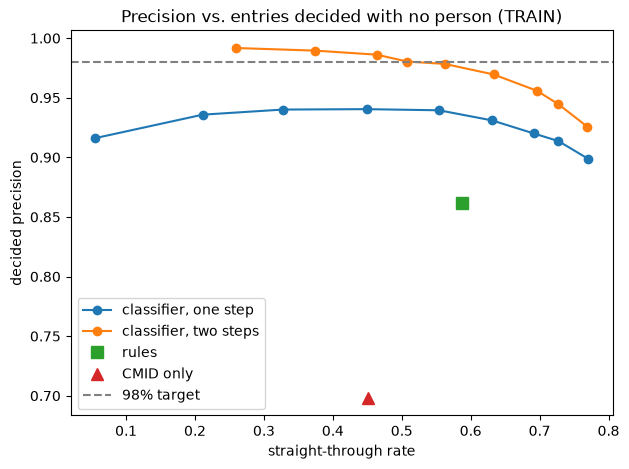

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, sweep, cfg, fixed in [("one step", one_sweep, one_step, ["multi_min", "no_match_max"]),
                                ("two steps", two_sweep, strict, ["no_match_min"])]:
    curve = sweep.xs(tuple(cfg[k] for k in fixed), level=fixed)
    ax.plot(curve["straight_through"], curve["decided_precision"], marker="o", label=f"classifier, {name}")
for method, marker in [("rules", "s"), ("CMID only", "^")]:
    row = baseline.query("method == @method and split == 'TRAIN' and entry_set == 'all'").iloc[0]
    ax.plot(row["straight_through"], row["decided_precision"], marker=marker, markersize=9, linestyle="", label=method)
ax.axhline(PRECISION_TARGET, color="gray", linestyle="--", label="98% target")
ax.set(title="Precision vs. entries decided with no person (TRAIN)", xlabel="straight-through rate", ylabel="decided precision")
ax.legend()
plt.show()

- **The two-step line sits above the one-step line everywhere** and crosses the 98% target, which one step never reaches.
- At the strict cutoffs, step 2 decides 51% of entries with no person (vs. 45% for one step) at much higher precision (98.0% vs. 94.0%).
- The rules sit well below both classifier lines.

## 8. The strict classifier on TRAIN

Rows are what the answer key expects and columns are what the classifier decided.

In [14]:
scored_train = score(route_actions(entries_train, action_cv, strict), answers)
pd.crosstab(scored_train["key_expected_action"], scored_train["action"]).reindex(index=ACTIONS, columns=ACTIONS, fill_value=0)

action,AUTO_MATCH,FLAG_MISMATCH,NEEDS_REVIEW,MULTI_MATTER,NO_MATCH
key_expected_action,,,,,
AUTO_MATCH,1275,123,644,76,2
FLAG_MISMATCH,6,130,25,7,0
NEEDS_REVIEW,55,0,108,2,1
MULTI_MATTER,11,1,26,136,0
NO_MATCH,2,0,97,3,72


In [15]:
wrong = scored_train[scored_train["outcome"] == "Accepted, wrong"]
wrong["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

,wrong auto-accepts
key_entry_category,
MULTI_NAMED,11
WRONG_CMID_TEXT,6
NO_MATCH,2
WRONG_CMID_SILENT,2
AMBIGUOUS,2
MESSY,1
INCOMPLETE,1


- **Most multi-matter entries are caught:** 136 of 174 get the call. Of the rest, 26 go to review, 11 are auto-matched to one matter, and 1 is flagged.
- **The price is false alarms:** 88 one-matter entries also get the call (mostly block-billed ones). Each costs a reviewer a few seconds to clear.
- **Wrong auto-accepts stay low:** 25, vs. 69 for one step. Eleven are named multi-matter entries, and the rest are spread across wrong CMIDs, new clients, and vague entries.
- **Review is the biggest bucket** (32% of TRAIN), and about 7 in 10 reviewed entries should have been auto-matched, so most reviews are a quick confirmation.

## 9. Which clues matter? (step 1)

Each group of clues from notebook 02 is dropped in turn, the step-1 model is retrained with the same settings, and the change in cross-validated top-1 accuracy is recorded. A big drop means the model leans on that group. This retrains the model 40 times, so it takes a few minutes.

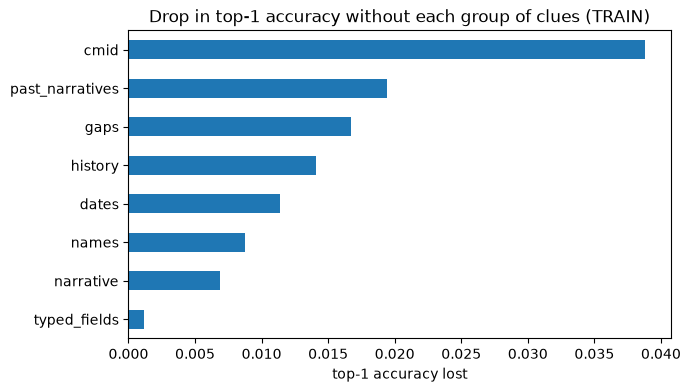

In [16]:
full_top_1 = model_scores.loc[chosen_model, "top_1"]

drop = {}
for group, cols in feature_groups.items():
    kept = [c for c in FEATURES if c not in cols]
    p = cross_val_predict(clone(best_model), X_train[kept], y_train, cv=cv, method="predict_proba")[:, 1]
    drop[group] = full_top_1 - top_k_accuracy(train_pairs, p, k=1)

ax = pd.Series(drop).sort_values().plot.barh(figsize=(7, 4), title="Drop in top-1 accuracy without each group of clues (TRAIN)")
ax.set_xlabel("top-1 accuracy lost")
plt.show()

- **The CMID clues matter most**, then **past narratives** and the gaps to the best candidate (about 2 points of top-1 each), then timekeeper history and dates (about 1 point each), then typed names and the other narrative clues (under 1 point each).
- Past narratives, built from billing history instead of a curated key-term list, are the second most useful group of clues.
- Dropping the typed-field flags barely changes anything, likely because the gap columns and CMID clues already carry the same information.

## 10. Check on VAL (once)

Both models were refit on all of TRAIN. VAL goes through both steps with the cutoffs from sections 6 and 7, and nothing changes after this. The interval is a 95% bootstrap range for decided precision: with about 600 entries, differences of 2 to 3 points can be noise.

In [17]:
val_probs = best_model.predict_proba(val_pairs[FEATURES])[:, 1]
entries_val = entry_features(val_pairs, val_probs, CLIENT_COL, MATTER_COL)
entries_val["multi_text_score"] = text_model.predict_proba(entries_val["entry_id"].map(narratives))[:, 1]
action_val = pd.DataFrame(action_model.predict_proba(entries_val[ACTION_FEATURES]), columns=action_model.classes_)

runs = {("classifier, one step", "TRAIN"): scored_one,
        ("classifier, one step", "VAL"): score(route(top_candidates(val_pairs, val_probs), one_step), answers),
        ("classifier (strict)", "TRAIN"): scored_train,
        ("classifier (strict)", "VAL"): score(route_actions(entries_val, action_val, strict), answers),
        ("classifier (balanced)", "TRAIN"): score(route_actions(entries_train, action_cv, balanced), answers),
        ("classifier (balanced)", "VAL"): score(route_actions(entries_val, action_val, balanced), answers)}

rows = {}
for (method, split), scored in runs.items():
    rows[(method, split, "all")] = summarize(scored)
    rows[(method, split, "non-trivial")] = summarize(scored[scored["key_trivial"] == "N"])
new_rows = pd.DataFrame(rows).T.rename_axis(["method", "split", "entry_set"]).reset_index()
comparison = pd.concat([baseline[~baseline["method"].str.startswith("classifier")], new_rows], ignore_index=True)

val_runs = {"CMID only": score(run_rules(val_pairs, rules_config["rules"], cmid_only), answers),
            "rules": score(run_rules(val_pairs, rules_config["rules"]), answers)}
val_runs |= {method: scored for (method, split), scored in runs.items() if split == "VAL"}

val_table = pd.DataFrame({name: summarize(scored) for name, scored in val_runs.items()}).T
val_table[["ci_low", "ci_high"]] = [precision_ci(scored) for scored in val_runs.values()]
val_table[["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "silent_by_design",
           "multi_share", "multi_flag_right", "multi_caught", "no_match_precision", "shortlist_hit"]].round(3)

,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,silent_by_design,multi_share,multi_flag_right,multi_caught,no_match_precision,shortlist_hit
CMID only,0.687,0.629,0.741,0.431,0.569,81.0,32.0,0.000,NaN,0.000,NaN,0.690
rules,0.871,0.835,0.906,0.566,0.329,36.0,17.0,0.023,0.643,0.243,0.771,0.606
"classifier, one step",0.963,0.940,0.981,0.446,0.443,9.0,1.0,0.037,0.182,0.108,0.933,0.887
classifier (strict),0.984,0.969,0.997,0.532,0.301,4.0,3.0,0.082,0.551,0.730,0.941,0.856
classifier (balanced),0.920,0.895,0.942,0.809,0.025,30.0,8.0,0.082,0.551,0.730,0.763,0.600


In [22]:
main = {name: scored for name, scored in val_runs.items() if name != "CMID only"}
accuracy = pd.DataFrame({name: {"matter_accuracy": scored["matter_right"].mean(),
                                "non_trivial": scored.loc[scored["key_trivial"] == "N", "matter_right"].mean(),
                                "action_accuracy": scored["action_right"].mean(),
                                "silent_errors": (scored["outcome"] == "Accepted, wrong").sum()}
                         for name, scored in main.items()}).T
val_table[["decided_precision", "straight_through"]].join(accuracy, how="inner").round(3)

,decided_precision,straight_through,matter_accuracy,non_trivial,action_accuracy,silent_errors
rules,0.871,0.566,0.651,0.556,0.631,36.0
"classifier, one step",0.963,0.446,0.835,0.790,0.506,9.0
classifier (strict),0.984,0.532,0.860,0.815,0.611,4.0
classifier (balanced),0.920,0.809,0.870,0.828,0.802,30.0


In [23]:
from sklearn.metrics import classification_report

for name in ["classifier (strict)", "classifier (balanced)"]:
    scored = val_runs[name]
    hard = scored["key_trivial"] == "N"
    print(f"# {name}\n== VAL ==")
    print(f"matter accuracy {scored['matter_right'].mean():.3f} | non-trivial {scored.loc[hard, 'matter_right'].mean():.3f} | "
          f"silent errors {(scored['outcome'] == 'Accepted, wrong').sum()}")
    print(f"action accuracy {scored['action_right'].mean():.3f}")
    print(classification_report(scored["key_expected_action"], scored["action"], digits=3, zero_division=0))

# classifier (strict)
== VAL ==
matter accuracy 0.860 | non-trivial 0.815 | silent errors 4
action accuracy 0.611
               precision    recall  f1-score   support

   AUTO_MATCH      0.931     0.623     0.746       453
FLAG_MISMATCH      0.549     0.778     0.644        36
 MULTI_MATTER      0.551     0.730     0.628        37
 NEEDS_REVIEW      0.077     0.368     0.128        38
     NO_MATCH      0.941     0.432     0.593        37

     accuracy                          0.611       601
    macro avg      0.610     0.586     0.548       601
 weighted avg      0.831     0.611     0.684       601

# classifier (balanced)
== VAL ==
matter accuracy 0.870 | non-trivial 0.828 | silent errors 30
action accuracy 0.802
               precision    recall  f1-score   support

   AUTO_MATCH      0.888     0.879     0.883       453
FLAG_MISMATCH      0.549     0.778     0.644        36
 MULTI_MATTER      0.551     0.730     0.628        37
 NEEDS_REVIEW      0.000     0.000     0.000      

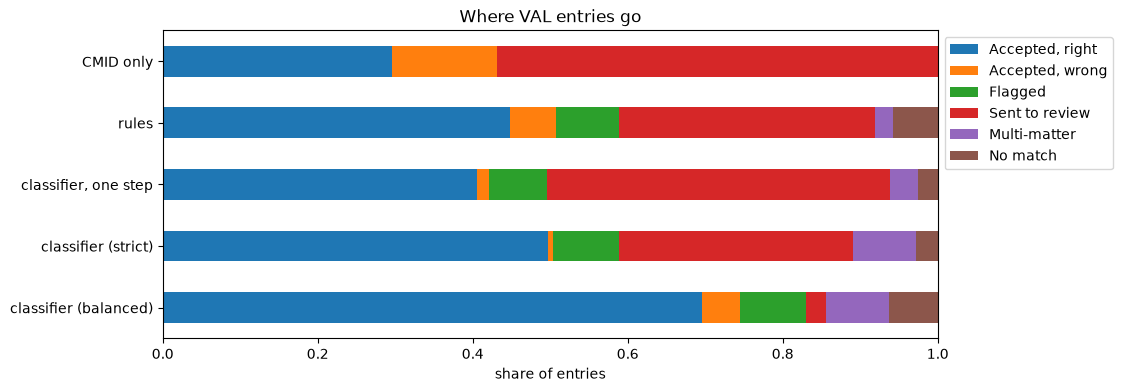

In [18]:
shares = pd.DataFrame({name: scored["outcome"].value_counts(normalize=True) for name, scored in val_runs.items()}).T[OUTCOMES].fillna(0)
ax = shares.plot.barh(stacked=True, figsize=(10, 4), xlim=(0, 1), title="Where VAL entries go")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

- **Strict vs. rules on VAL:** decided precision 98.4% (range 96.9 to 99.7%) vs. 87.1% (83.5 to 90.6%), and silent errors drop from 36 to 4. The ranges don't overlap, so the gain is real.
- **Similar workload, far fewer mistakes:** strict decides 53% of entries with no person vs. 57% for the rules. The gain is accuracy, not less work.
- **Strict vs. one step:** more entries decided with no person (53% vs. 45%) at higher precision (98.4% vs. 96.3%), mostly because multi-matter entries are recognized.
- **Balanced vs. rules:** higher precision (92.0% vs. 87.1%), 81% of entries decided with no person instead of 57%, and 3% sent to review instead of 33%.
- **`MULTI_MATTER`:** 73% of multi-matter entries are caught and about half the calls are right (the rules: 24% caught, 64% right).
- **Matter and action accuracy:** balanced picks the right matter for 87% of VAL entries (83% of non-trivial ones) and the expected action for 80%, vs. 65% and 63% for the rules. Strict has lower action accuracy (61%) because it sends some entries it has right to review on purpose.
- **Reviewed entries are quick checks:** the true matter is in the top 3 for 86% of reviewed entries under strict, vs. 61% for the rules. 94% of strict `NO_MATCH` calls are right.
- VAL matches TRAIN closely, so the models and cutoffs didn't overfit.

## 11. Reasons for each decision

A reviewer needs to know why the tool chose what it chose, but won't read a paragraph for every entry. So each decision gets two reasons, built by `explain` from that entry's own clues:
- **`reason_short`:** a few words for the review list ("Typed CMID matches", "Client clear, matter unclear")
- **`reason_full`:** the decision, a confidence level from the top pick's probability (high 0.9+, medium 0.5+, low), the top pick's strongest clues, and the shortlist. For a multi-matter call, it also suggests which piece of work goes to which matter, from the parts table.

Clues are listed in the order the model leans on them most (section 9), and only clues that are actually present for that entry are shown, so the reason always matches what the model saw.

In [19]:
parts["other_work_score"] = text_model.predict_proba(parts["part_norm"])[:, 1]
inputs = {"TRAIN": (entries_train, train_pairs), "VAL": (entries_val, val_pairs)}
for method, split in runs:
    if method == "classifier, one step":
        continue
    entries, table = inputs[split]
    runs[(method, split)] = explain(runs[(method, split)], entries, table, CLIENT_COL, MATTER_COL, feature_config["phrase_min"], parts)

strict_val = runs[("classifier (strict)", "VAL")]
for _, row in strict_val.groupby("action").head(2).sort_values("action").iterrows():
    print(f"{row['action']:<14} {row['reason_short']}\n{'':<14} {row['reason_full']}\n")

AUTO_MATCH     Reads like past entries
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the narrative reads like past entries on this matter; the timekeeper billed 125.4 hours to it recently; the typed client matches Meridian Therapeutics.

AUTO_MATCH     Typed CMID matches
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the typed CMID is this matter; the narrative reads like past entries on this matter; the timekeeper billed 125.4 hours to it recently.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), low confidence: the timekeeper billed 5.5 hours to it recently; the typed client matches Meridian Therapeutics.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 8340.001 (Pelican Row Holdings - Acquis

In [20]:
strict_val.groupby("action")["reason_short"].value_counts().rename("VAL entries").to_frame()

VAL entries
action        reason_short                                 
AUTO_MATCH    Typed CMID matches                        128
              Reads like past entries                   126
              You've billed this matter                  35
              Typed client matches                       11
              Typed matter matches                        2
              Narrative names the matter                  1
FLAG_MISMATCH Typed CMID doesn't fit narrative           51
MULTI_MATTER  May cover two matters                      37
              Mentions other work                        12
NEEDS_REVIEW  Not sure enough to accept                 102
              No clear match                             35
              Client clear, matter unclear               32
              Close call between matters                 12
NO_MATCH      Likely a new client or matter              17

- **Every decision says why in a few words.** Auto-matches mostly cite the typed CMID (128 of 303) or past entries on the matter (126), and flags point out that the typed CMID doesn't fit the narrative.
- **Review reasons tell the reviewer where to look:** the client is clear but the matter isn't, two matters are close, or nothing points anywhere. "Not sure enough to accept" is still the most common (102 of 181): the top pick has some support, and the shortlist and clues in the full reason are the guide.
- **Split suggestions** put the part that seems to be other work on its own, so the timekeeper only has to confirm the second matter and divide the hours. When the call is a false alarm, the suggestion makes that quick to see.

## 12. Save

- `04_decisions.csv`: one row per TRAIN and VAL entry for each classifier version (`method` column), with both reasons, top probabilities, and shortlist. Same columns as `03_decisions.csv` where they overlap, so any later method can be scored the same way.
- `03_comparison.csv`: now also has the classifier's rows
- `04_config.json`: the chosen model, its settings, and all cutoffs
- `04_model.joblib`: the three trained models (pairs, narrative text, action), for the app and later notebooks

In [21]:
decisions = pd.concat([scored.assign(method=method) for (method, split), scored in runs.items()], ignore_index=True)
decisions.to_csv(RESULTS_DIR / "04_decisions.csv", index=False)
comparison.to_csv(RESULTS_DIR / "03_comparison.csv", index=False)
joblib.dump({"pair_model": best_model, "text_model": text_model, "action_model": action_model}, RESULTS_DIR / "04_model.joblib")

config = {"model": chosen_model, "model_params": searches[chosen_model].best_params_, "features": FEATURES,
          "action_features": ACTION_FEATURES, "text_model_params": text_search.best_params_,
          "action_model_params": action_search.best_params_, "routing": {"one_step": one_step, "strict": strict, "balanced": balanced},
          "multi_beta": MULTI_BETA, "precision_target": PRECISION_TARGET}
(RESULTS_DIR / "04_config.json").write_text(json.dumps(config, indent=2, default=str))
print("Saved:", ", ".join(p.name for p in sorted(RESULTS_DIR.glob("04_*"))), "+ 03_comparison.csv")

Saved: 04_config.json, 04_decisions.csv, 04_model.joblib + 03_comparison.csv


## 13. Findings

- **Step 1 (scoring pairs):** tuned gradient boosting ranks the right matter first for 92% of entries and in the top 3 for 97%, with well-calibrated probabilities.
- **One step tops out around 94% on TRAIN**, because a cutoff on one candidate's probability can't tell when an entry covers two matters.
- **Step 2 (deciding the action) reaches the 98% target** on TRAIN (98.0%) and gets 98.4% on VAL (range 96.9 to 99.7%), deciding about half of entries with no person.
- **The `MULTI_MATTER` call catches 73% of multi-matter entries on VAL**, using a narrative text score and a cutoff learned by F2, which counts a missed second matter as worse than a false alarm.
- **Compared with the rules,** strict keeps a similar workload and cuts silent errors by about 90% (36 to 4), and balanced decides 81% of entries with no person at higher precision than the rules.
- **Every decision comes with a short reason** for the review list and a full one with the clues, shortlist, or suggested split.
- **Realistic clues are enough:** key terms from matter names and past narratives from billing history, with no curated key-term list.

## Limitations

- The data is synthetic, and the models learn its patterns closely. The text model in particular learns the phrase bank's wording for other work, so real entries will likely score lower and the models would need retraining on real labeled entries.
- Matter type and dates are assumed to be in the firm's matter list.
- About 4 to 5 in 10 `MULTI_MATTER` calls are false alarms, mostly block-billed entries. If multi-matter entries are rarer at a real firm, that share will be higher, and `MULTI_BETA` can be lowered.
- About 1 in 4 multi-matter entries isn't caught. Those go to review, where a reviewer could confirm one matter and miss the second.
- Strict sits right at the 98% line, so small changes to the training data can move its cutoffs. The precision range on VAL says more than the exact number.
- Reasons list the clues present for an entry in the order the model leans on them overall, not by how much each one moved that entry's score.
- Results come from about 600 VAL entries, so small differences between settings aren't meaningful.

## Next steps

- Choose an operating point (strict, balanced, or in between) based on how many silent errors and how much review a firm will accept.
- Check the reasons and split suggestions with billing staff: are they short and clear enough to act on?
- Run the final comparison once on TEST and the holdout file, which has new phrasings and a timekeeper with no history.